# Лабораторная работа №2: Детекция и сегментация объектов
## Стрельченко Алексей Александрович

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Проверить разметку и распределения объектов.
- Дообучить компактный segmentation baseline.
- Сравнить аугментации и проанализировать ошибки.


## Теоретическая часть

В детекции модель предсказывает классы и bounding boxes, в сегментации — метку каждого пикселя. Для класса $c$ качество сегментации измеряет $IoU_c=|P_c\cap G_c|/|P_c\cup G_c|$. Для детекции mAP усредняет AP по классам и порогам IoU.

![Segmentation example](https://pytorch.org/vision/main/_images/sphx_glr_plot_visualization_utils_008.png)


### Математическая постановка

Составная функция потерь может иметь вид
$$\mathcal L=\mathcal L_{cls}+\lambda_{box}\mathcal L_{box}+\lambda_{mask}\mathcal L_{mask}.$$
Разбиение должно выполняться по исходным объектам/сериям, иначе соседние кадры дают утечку.


### Материалы

- [Torchvision segmentation models](https://pytorch.org/vision/stable/models.html#semantic-segmentation)
- [COCO metrics](https://cocodataset.org/#detection-eval)
- [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Проверить разметку и распределения объектов.
2. Дообучить компактный segmentation baseline.
3. Сравнить аугментации и проанализировать ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** LRASPP-MobileNetV3 или FCN-ResNet50, mixed precision.
- **Ограничение данных:** Oxford-IIIT Pet или до 2 000 изображений; в smoke-режиме — синтетический датасет.
- **Fallback:** замороженный backbone и 256 px.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# ============================================================
# Базовое воспроизводимое окружение + поиск data/ относительно ноутбука
# ============================================================
from pathlib import Path
import json, os, random, time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from torchvision.models.segmentation import (
    lraspp_mobilenet_v3_large,
    LRASPP_MobileNet_V3_Large_Weights,
)

SEED = 42
FAST_DEV_RUN = False  # True — только smoke-проверка, отчёт идёт по полному запуску
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Поиск каталога с данными ------------------------------------------------
# Структура проекта:
#   <repo_root>/SOTA_labs/lab2/Strelchenko_A_A_lab2.ipynb   <- этот ноутбук
#   <repo_root>/data                                        <- сюда качаем датасеты
#   <repo_root>/SOTA_labs/lab2/artifacts                    <- артефакты
#
# Ноутбук может запускаться из <repo_root>/SOTA_labs/lab2 или из корня —
# поэтому проверяем несколько кандидатов по порядку.
CWD = Path.cwd().resolve()
_CANDIDATES = [
    CWD / "data",                # data рядом с ноутбуком
    CWD.parent / "data",         # <repo_root>/SOTA_labs/data
    CWD.parent.parent / "data",  # <repo_root>/data
]


def _has_datasets(p: Path) -> bool:
    """Каталог считается валидным, если в нём уже лежит хоть что-то из датасетов курса."""
    if not p.is_dir():
        return False
    markers = ["oxford_pet", "cifar-10-batches-py", "oxford-iiit-pet"]
    return any((p / m).exists() for m in markers)


# Приоритет: явная переменная окружения → существующий каталог → создаём рядом с ноутбуком
_env = os.getenv("CV_COURSE_DATA")
if _env:
    DATA_ROOT = Path(_env).resolve()
elif (found := next((c for c in _CANDIDATES if _has_datasets(c)), None)):
    DATA_ROOT = found
else:
    # Ничего не найдено — создаём data рядом с ноутбуком (первый кандидат)
    DATA_ROOT = _CANDIDATES[0]

DATA_ROOT.mkdir(parents=True, exist_ok=True)

# ---- Каталог артефактов: рядом с ноутбуком --------------------------------
# Если запускаете из lab2/, артефакты лягут в SOTA_labs/lab2/artifacts.
# Если из корня репозитория — в ./artifacts. Можно переопределить через CV_ARTIFACTS.
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", CWD / "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

print({
    "cwd":         str(CWD),
    "device":      DEVICE,
    "fast_dev_run": FAST_DEV_RUN,
    "data_root":   str(DATA_ROOT),
    "artifacts":   str(ARTIFACTS),
})

{'cwd': 'C:\\Users\\User\\Desktop\\ml_labs\\SOTA_labs\\lab2', 'device': 'cpu', 'fast_dev_run': False, 'data_root': 'C:\\Users\\User\\Desktop\\ml_labs\\SOTA_labs\\data', 'artifacts': 'C:\\Users\\User\\Desktop\\ml_labs\\SOTA_labs\\lab2\\artifacts'}


In [2]:
def check(condition, message):
    """Молчит, если всё хорошо; иначе печатает предупреждение."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Маски Oxford-IIIT Pet

*Вес: 1 балл.*

**Постановка.** Сегментатор обучается на реальной пиксельной разметке.

Выполните следующие действия:
1. Загрузите trainval Oxford-IIIT Pet и совместно масштабируйте изображение и маску.
2. Убедитесь, что интерполяция маски сохраняет классы.

**Результат.** Датасет ds и преобразования img_tf, mask_tf.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


100.0%
100.0%


✔ Классы в маске после ресайза и нормализации: [0, 1, 2]
✔ Формы: img=(3, 256, 256), mask=(256, 256)


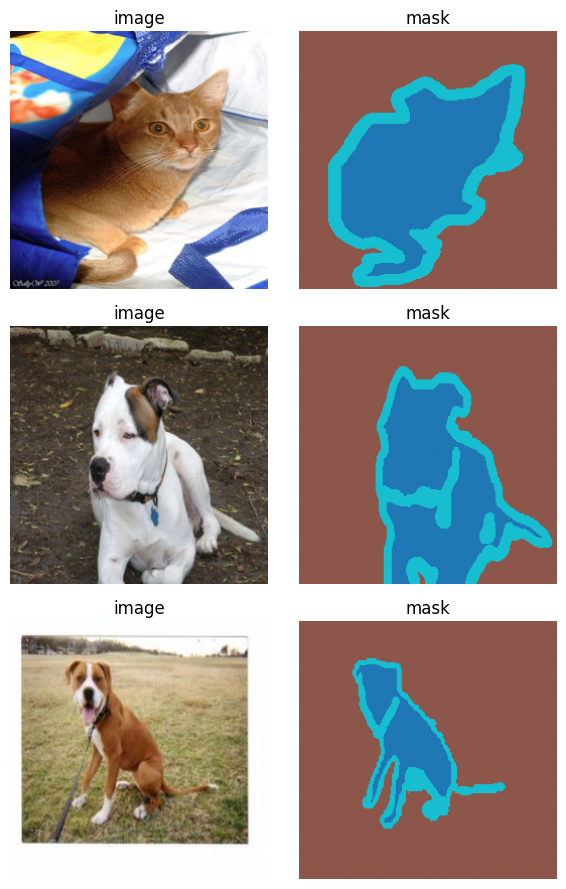

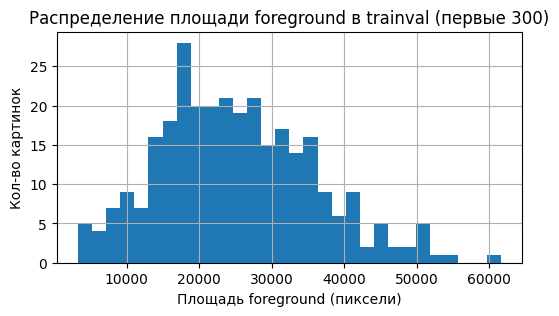

In [3]:
# ============================================================
# ЗАДАНИЕ 1. Загрузка Oxford-IIIT Pet с пиксельной разметкой
# ============================================================
PET_ROOT = DATA_ROOT / "oxford_pet"
IMG_SIZE = 256
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]


def normalize_mask(mask):
    """Перекодировка исходных меток 1..3 (1=pet, 2=bg, 3=border) в 0..2."""
    mask = torch.as_tensor(np.array(mask), dtype=torch.long)
    return mask - 1


class JointTransform:
    """
    Совместное преобразование изображения и маски.
    Маску ресайзим строго через NEAREST-интерполяцию, чтобы НЕ размывать классы.
    Изображение — через BILINEAR.
    """
    def __init__(self, size=IMG_SIZE, augment=False):
        self.size = size
        self.augment = augment  # True — синхронный hflip (пригодится в задании 6)

    def __call__(self, img, mask):
        img  = TF.resize(img,  [self.size, self.size], interpolation=InterpolationMode.BILINEAR)
        mask = TF.resize(mask, [self.size, self.size], interpolation=InterpolationMode.NEAREST)
        if self.augment and random.random() < 0.5:
            img  = TF.hflip(img)     # важно: преобразование применяем и к изображению,
            mask = TF.hflip(mask)    # и к маске — иначе маска «съедет» относительно картинки
        img  = TF.normalize(TF.to_tensor(img), MEAN, STD)
        mask = normalize_mask(mask)
        return img, mask


class PetSegDataset(Dataset):
    """Обёртка над OxfordIIITPet: возвращает (image_tensor, mask_long)."""
    def __init__(self, root, split="trainval", augment=False):
        self.base = OxfordIIITPet(root, split=split, target_types="segmentation", download=True)
        self.tf = JointTransform(IMG_SIZE, augment=augment)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, mask = self.base[idx]
        return self.tf(img, mask)


# Основной датасет trainval
ds = PetSegDataset(PET_ROOT, split="trainval", augment=False)

# --- Контроль: интерполяция маски не создала «мусорных» классов ---
img0, m0 = ds[0]
uniq = sorted(torch.unique(m0).tolist())
check(set(uniq).issubset({0, 1, 2}),
      f"Классы в маске после ресайза и нормализации: {uniq}")
check(img0.shape == (3, IMG_SIZE, IMG_SIZE) and m0.shape == (IMG_SIZE, IMG_SIZE),
      f"Формы: img={tuple(img0.shape)}, mask={tuple(m0.shape)}")

# --- Визуальная проверка (3 случайных примера) ---
mean_t = torch.tensor(MEAN).view(3, 1, 1)
std_t  = torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(3, 2, figsize=(6, 9))
for row in range(3):
    img, m = ds[(row * 71) % len(ds)]
    img_vis = (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    axes[row, 0].imshow(img_vis); axes[row, 0].set_title("image"); axes[row, 0].axis("off")
    axes[row, 1].imshow(m, vmin=0, vmax=2, cmap="tab10"); axes[row, 1].set_title("mask"); axes[row, 1].axis("off")
plt.tight_layout(); plt.show()

# --- Распределение площадей масок по trainval (наглядно видно дисбаланс классов) ---
areas = np.array([int(((ds[i][1] == 0) | (ds[i][1] == 2)).sum()) for i in range(min(len(ds), 300))])
plt.figure(figsize=(6, 3))
plt.hist(areas, bins=30)
plt.xlabel("Площадь foreground (пиксели)"); plt.ylabel("Кол-во картинок")
plt.title("Распределение площади foreground в trainval (первые 300)")
plt.grid(True); plt.show()

In [ ]:
# ============================================================
# Примеры из trainval: 12 картинок + маски
# ============================================================
import matplotlib.pyplot as plt

N_SHOW = 12                      # сколько примеров показать (кратно 2)
COLS   = 4                       # 4 пары в ряд => 8 колонок
ROWS   = N_SHOW // COLS

# Равномерно по датасету — увидим разные породы, а не подряд идущие коты
idxs = np.linspace(0, len(ds) - 1, N_SHOW).astype(int)

fig, axes = plt.subplots(ROWS, COLS * 2, figsize=(COLS * 3.2, ROWS * 3.0))
for k, i in enumerate(idxs):
    img, m = ds[i]
    img_vis = (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    r, c = divmod(k, COLS)
    axes[r, c * 2].imshow(img_vis)
    axes[r, c * 2].set_title(f"#{i}", fontsize=9)
    axes[r, c * 2].axis("off")
    axes[r, c * 2 + 1].imshow(m, vmin=0, vmax=2, cmap="tab10")
    axes[r, c * 2 + 1].set_title("mask", fontsize=9)
    axes[r, c * 2 + 1].axis("off")
plt.suptitle("Oxford-IIIT Pet — примеры trainval (image | mask)", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

### Разделение и кодирование меток

*Вес: 1 балл.*

**Постановка.** Оценка на validation требует непересекающихся индексов и корректных категориальных меток.

Выполните следующие действия:
1. Разделите trainval на train и validation.
2. Перекодируйте исходные метки 1–3 в 0–2 и соберите загрузчики.

**Результат.** train_ds, val_ds, loader, val_loader и normalize_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
# ============================================================
# ЗАДАНИЕ 2. Разделение train/val и загрузчики
# ============================================================
n_total = len(ds)
n_val   = max(1, int(0.2 * n_total))

# В FAST_DEV_RUN берём маленькую подвыборку — это лишь smoke-проверка связности
if FAST_DEV_RUN:
    n_total = min(n_total, 150)
    n_val   = max(1, min(n_val, 30))

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(n_total, generator=g).tolist()
val_idx   = perm[:n_val]
train_idx = perm[n_val:]

train_ds = Subset(ds, train_idx)
val_ds   = Subset(ds, val_idx)

BATCH_SIZE = 8
loader     = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

check(len(train_ds) > 0 and len(val_ds) > 0,
      f"Разбиение: train={len(train_ds)}, val={len(val_ds)}, пересечение индексов = {len(set(train_idx) & set(val_idx))}")

# Проверка класса метки в батче (после перекодировки — 0/1/2)
_x, _y = next(iter(loader))
check(set(torch.unique(_y).tolist()).issubset({0, 1, 2}),
      f"Классы в батче train: {sorted(torch.unique(_y).tolist())}")

✔ Разбиение: train=2944, val=736, пересечение индексов = 0
✔ Классы в батче train: [0, 1, 2]


### Сегментатор и IoU

*Вес: 1 балл.*

**Постановка.** Пиксельная модель предсказывает логиты для каждого класса.

Выполните следующие действия:
1. Замените головы LRASPP на трёхклассовые.
2. Реализуйте IoU по пересечению и объединению масок.

**Результат.** Объект model и функция mean_iou.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
# ============================================================
# ЗАДАНИЕ 3. Модель LRASPP-MobileNetV3 с 3-классовой головой + IoU
# ============================================================
def build_model(num_classes=3):
    """
    Скачиваем LRASPP-MobileNetV3 с весами COCO_VOC, затем заменяем обе
    головы (low/high) на 3-классовые — обучаем «с нуля» только их.
    """
    m = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1)
    m.classifier.low_classifier  = nn.Conv2d(40,  num_classes, kernel_size=1)
    m.classifier.high_classifier = nn.Conv2d(128, num_classes, kernel_size=1)
    return m

model = build_model(3).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Обучаемых параметров: {n_params/1e6:.2f}M")


def mean_iou(pred, target, num_classes=3):
    """
    mean IoU по классам для батча целочисленных тензоров формы (B,H,W).
    IoU_c = |pred==c ∩ target==c| / |pred==c ∪ target==c|.
    Классы, отсутствующие и в pred, и в target, в среднее не попадают.
    """
    ious = []
    for c in range(num_classes):
        p = (pred == c)
        t = (target == c)
        inter = (p & t).sum().item()
        union = (p | t).sum().item()
        if union == 0:
            continue
        ious.append(inter / union)
    return float(np.mean(ious)) if ious else 0.0


# --- Smoke-проверка: IoU идеального предсказания = 1.0 ---
_t = torch.randint(0, 3, (2, 8, 8))
check(abs(mean_iou(_t, _t.clone()) - 1.0) < 1e-9, "mean_iou на идеальном предсказании = 1.0")

# --- Smoke-проверка forward-прохода ---
with torch.no_grad():
    _out = model(torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE))
check(_out["out"].shape == (1, 3, IMG_SIZE, IMG_SIZE),
      f"Выход модели: {tuple(_out['out'].shape)}")

Downloading: "https://download.pytorch.org/models/lraspp_mobilenet_v3_large-d234d4ea.pth" to C:\Users\User/.cache\torch\hub\checkpoints\lraspp_mobilenet_v3_large-d234d4ea.pth


100.0%


Обучаемых параметров: 3.22M
✔ mean_iou на идеальном предсказании = 1.0
✔ Выход модели: (1, 3, 256, 256)


### Оптимизация сегментатора

*Вес: 1 балл.*

**Постановка.** Cross-entropy на масках задаёт обучающий сигнал каждому пикселю.

Выполните следующие действия:
1. Реализуйте шаг AdamW с обратным распространением.
2. Обучите модель установленное число эпох.

**Результат.** Функция train_one_epoch и массив history реальных значений loss.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


[base] epoch 1/5  loss=0.2878  (427.3s)
[base] epoch 2/5  loss=0.2194  (544.5s)
[base] epoch 3/5  loss=0.1982  (484.9s)
[base] epoch 4/5  loss=0.1874  (514.4s)
[base] epoch 5/5  loss=0.1714  (492.1s)


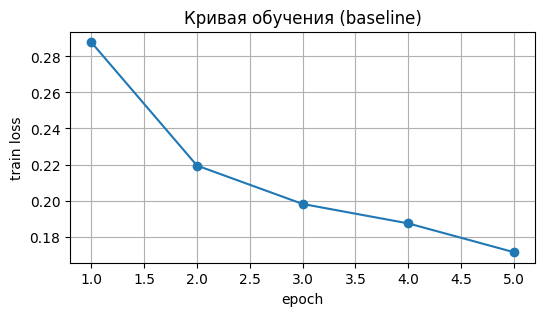

In [6]:
# ============================================================
# ЗАДАНИЕ 4. AdamW + CrossEntropy, обучение на несколько эпох
# ============================================================
criterion = nn.CrossEntropyLoss()                       # CE по каждому пикселю
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)


def train_one_epoch(model, loader, opt, crit, device):
    """Одна эпоха обучения. Возвращает средний loss по эпохе."""
    model.train()
    total, n = 0.0, 0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        opt.zero_grad()
        out = model(imgs)["out"]                        # (B, C, H, W)
        loss = crit(out, masks)                         # CE по пикселям
        loss.backward()
        opt.step()
        total += loss.item() * imgs.size(0)
        n += imgs.size(0)
    return total / max(1, n)


NUM_EPOCHS = 1 if FAST_DEV_RUN else 5
history = []
for ep in range(NUM_EPOCHS):
    t0 = time.time()
    loss = train_one_epoch(model, loader, optimizer, criterion, DEVICE)
    history.append(loss)
    print(f"[base] epoch {ep+1}/{NUM_EPOCHS}  loss={loss:.4f}  ({time.time()-t0:.1f}s)")

# --- Кривая обучения ---
plt.figure(figsize=(6, 3))
plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("epoch"); plt.ylabel("train loss"); plt.title("Кривая обучения (baseline)")
plt.grid(True); plt.show()

### Валидационный IoU

*Вес: 1 балл.*

**Постановка.** Матрица ошибок по пикселям позволяет вычислить классовый IoU.

Выполните следующие действия:
1. Накопите confusion matrix по validation.
2. Сохраните mIoU и checkpoint исходной модели.

**Результат.** segmentation.pt и val_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Confusion matrix (rows=gt, cols=pred):
 [[13940753   225750   592771]
 [  335692 26881715   727135]
 [ 1136204   901805  3492671]]
IoU по классам: {'pet': np.float64(0.8589), 'background': np.float64(0.9247), 'border': np.float64(0.5098)} | mIoU=0.7645


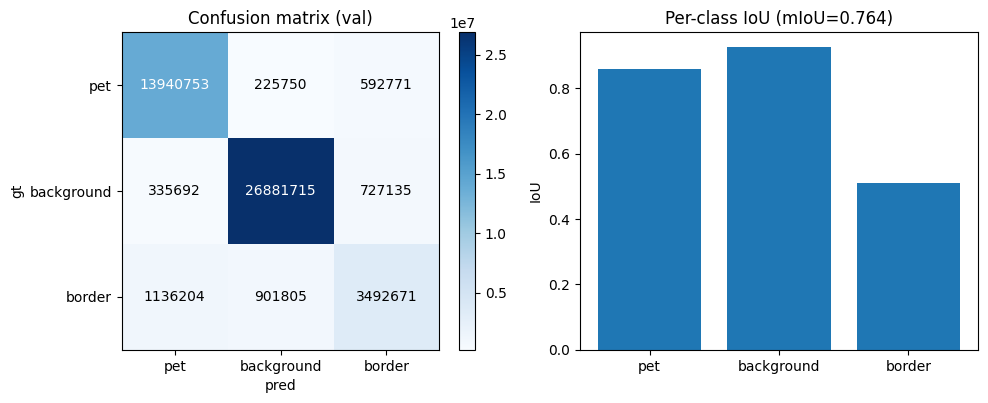

In [7]:
# ============================================================
# ЗАДАНИЕ 5. Confusion matrix по val, mIoU, checkpoint
# ============================================================
def evaluate_cm(model, loader, device, num_classes=3):
    """Накопление confusion matrix по пикселям на валидации."""
    model.eval()
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    with torch.no_grad():
        for imgs, masks in loader:
            imgs = imgs.to(device)
            pred = model(imgs)["out"].argmax(1).cpu().numpy().ravel()
            tgt  = masks.numpy().ravel()
            valid = (tgt >= 0) & (tgt < num_classes)
            idx = tgt[valid] * num_classes + pred[valid]
            cm += np.bincount(idx, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return cm


def iou_per_class(cm):
    """IoU по классам из confusion matrix."""
    ious = []
    for c in range(cm.shape[0]):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp
        denom = tp + fp + fn
        ious.append(tp / denom if denom > 0 else float("nan"))
    return np.array(ious)


cm      = evaluate_cm(model, val_loader, DEVICE)
per_cls = iou_per_class(cm)
miou    = float(np.nanmean(per_cls))
class_names = ["pet", "background", "border"]
print("Confusion matrix (rows=gt, cols=pred):\n", cm)
print("IoU по классам:", dict(zip(class_names, np.round(per_cls, 4))), f"| mIoU={miou:.4f}")

# --- Сохранение артефактов ---
torch.save(model.state_dict(), ARTIFACTS / "segmentation.pt")
with open(ARTIFACTS / "val_metrics.json", "w") as f:
    json.dump({
        "mIoU": miou,
        "per_class_iou": {n: float(v) for n, v in zip(class_names, per_cls)},
        "confusion_matrix": cm.tolist(),
        "history": history,
    }, f, indent=2, ensure_ascii=False)

# --- Визуализация confusion matrix и IoU по классам ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im = axes[0].imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, int(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black")
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(class_names)
axes[0].set_yticks(range(3)); axes[0].set_yticklabels(class_names)
axes[0].set_xlabel("pred"); axes[0].set_ylabel("gt")
axes[0].set_title("Confusion matrix (val)")
plt.colorbar(im, ax=axes[0])

axes[1].bar(class_names, per_cls)
axes[1].set_ylabel("IoU"); axes[1].set_title(f"Per-class IoU (mIoU={miou:.3f})")
plt.tight_layout(); plt.show()

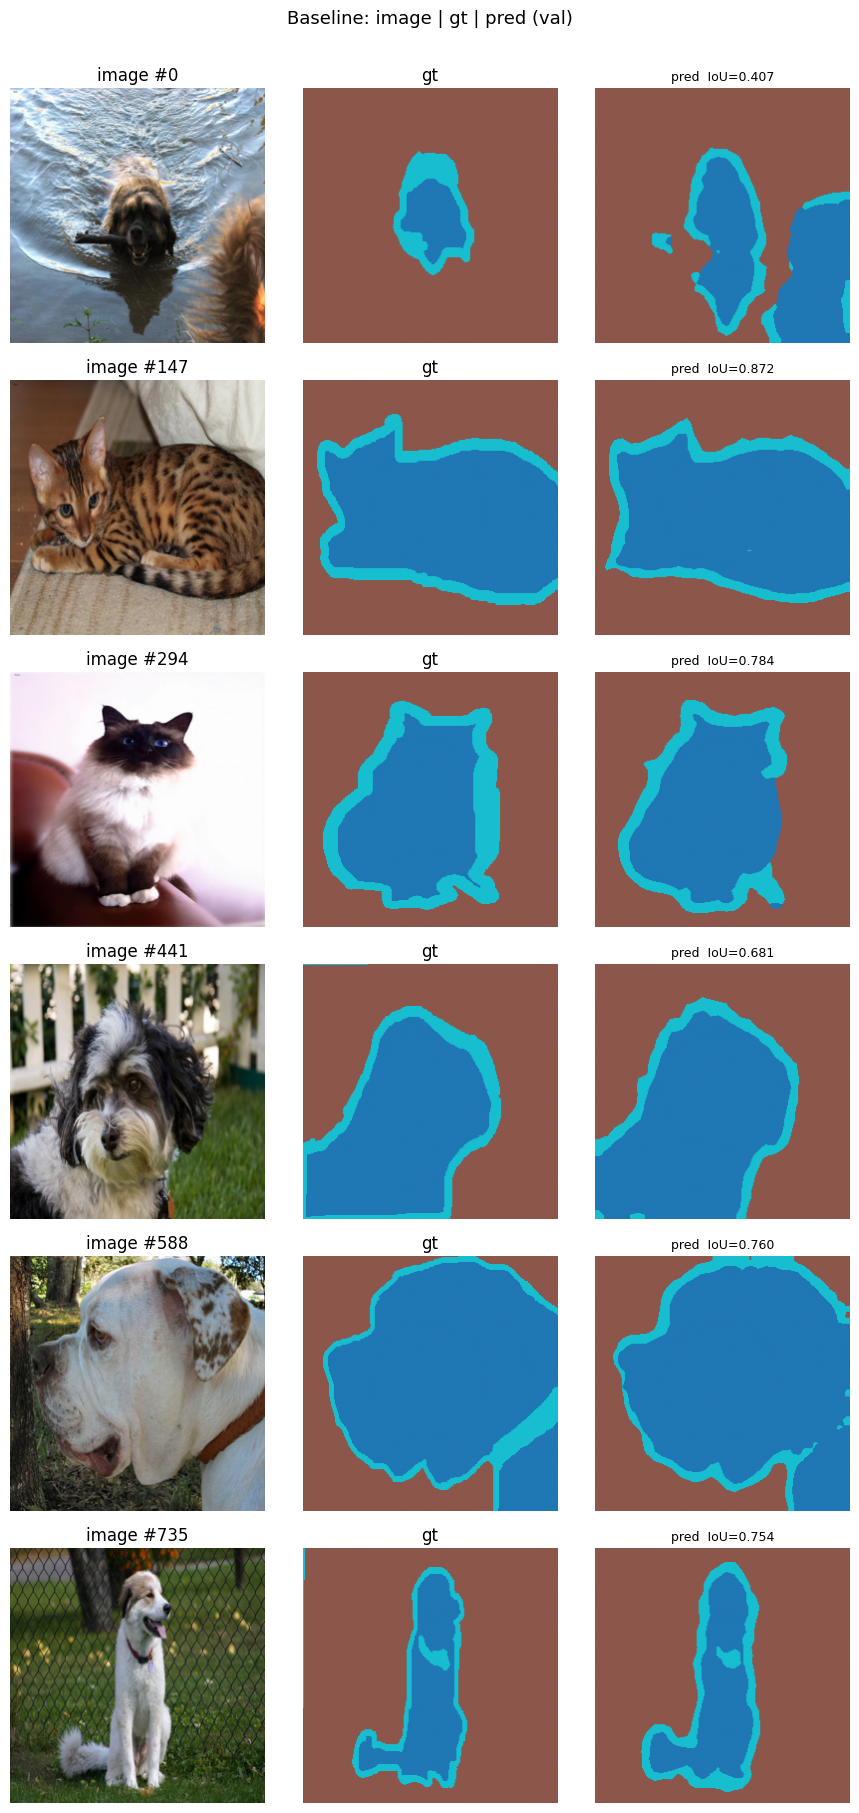

In [8]:
# ============================================================
# Предсказания baseline на val: image | gt | pred
# ============================================================
N_SHOW = 6
idxs_val = np.linspace(0, len(val_ds) - 1, N_SHOW).astype(int)

model.eval()
fig, axes = plt.subplots(N_SHOW, 3, figsize=(9, N_SHOW * 3))
for row, j in enumerate(idxs_val):
    img, mask = val_ds[j]
    with torch.no_grad():
        pred = model(img.unsqueeze(0).to(DEVICE))["out"].argmax(1)[0].cpu()
    img_vis = (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    iou_i = mean_iou(pred.unsqueeze(0), mask.unsqueeze(0))

    axes[row, 0].imshow(img_vis); axes[row, 0].set_title(f"image #{j}"); axes[row, 0].axis("off")
    axes[row, 1].imshow(mask, vmin=0, vmax=2, cmap="tab10")
    axes[row, 1].set_title("gt"); axes[row, 1].axis("off")
    axes[row, 2].imshow(pred, vmin=0, vmax=2, cmap="tab10")
    axes[row, 2].set_title(f"pred  IoU={iou_i:.3f}", fontsize=9); axes[row, 2].axis("off")

plt.suptitle("Baseline: image | gt | pred (val)", y=1.005, fontsize=13)
plt.tight_layout(); plt.show()

### Совместное отражение и повторное обучение

*Вес: 1 балл.*

**Постановка.** Геометрическое преобразование изображения без идентичного преобразования маски портит разметку.

Выполните следующие действия:
1. Реализуйте синхронное горизонтальное отражение.
2. Обучите новый сегментатор при том же бюджете и сравните validation mIoU.

**Результат.** segmentation_aug.pt и augmentation_comparison.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


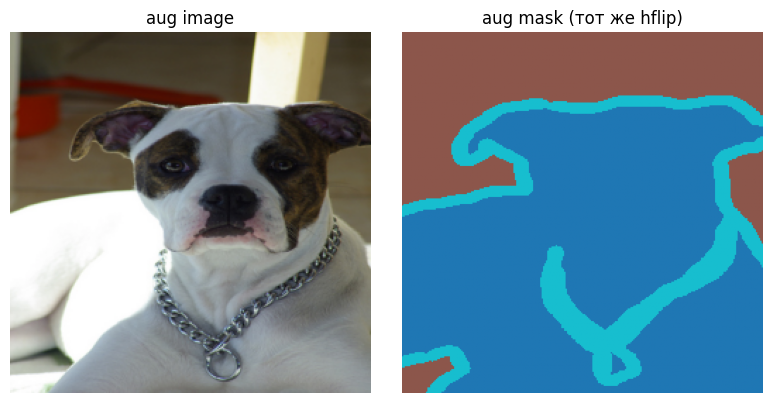

[aug ] epoch 1/5  loss=0.2900
[aug ] epoch 2/5  loss=0.2298
[aug ] epoch 3/5  loss=0.2094
[aug ] epoch 4/5  loss=0.1923
[aug ] epoch 5/5  loss=0.1892
baseline mIoU = 0.7645   |   hflip mIoU = 0.7531


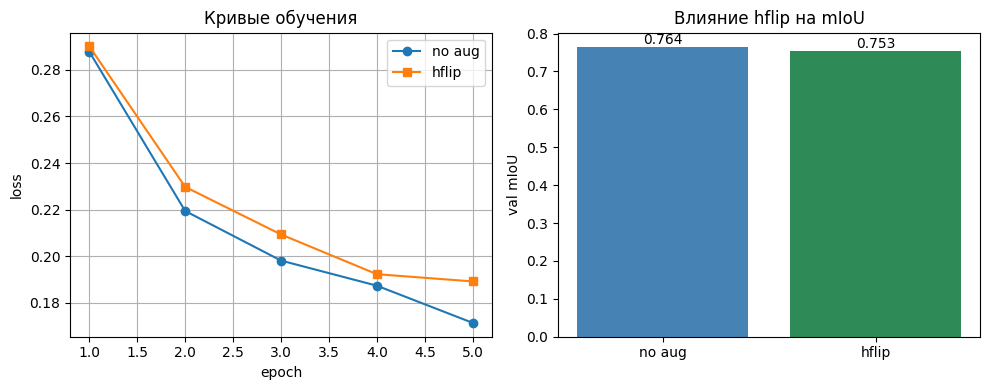

In [9]:
# ============================================================
# ЗАДАНИЕ 6. Синхронный hflip + повторное обучение с тем же бюджетом
# ============================================================
# Создаём тренировочный датасет С аугментацией (hflip применяется синхронно к img+mask)
train_ds_aug = Subset(PetSegDataset(PET_ROOT, split="trainval", augment=True), train_idx)
loader_aug   = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

# --- Быстрая демонстрация синхронности ---
img_a, m_a = train_ds_aug[0]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow((img_a * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
axes[0].set_title("aug image"); axes[0].axis("off")
axes[1].imshow(m_a, vmin=0, vmax=2, cmap="tab10")
axes[1].set_title("aug mask (тот же hflip)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

# --- Обучение второй модели с ТЕМ ЖЕ бюджетом ---
model_aug = build_model(3).to(DEVICE)
opt_aug   = torch.optim.AdamW(model_aug.parameters(), lr=1e-3, weight_decay=1e-4)

history_aug = []
for ep in range(NUM_EPOCHS):
    loss = train_one_epoch(model_aug, loader_aug, opt_aug, criterion, DEVICE)
    history_aug.append(loss)
    print(f"[aug ] epoch {ep+1}/{NUM_EPOCHS}  loss={loss:.4f}")

cm_aug      = evaluate_cm(model_aug, val_loader, DEVICE)
per_cls_aug = iou_per_class(cm_aug)
miou_aug    = float(np.nanmean(per_cls_aug))
print(f"baseline mIoU = {miou:.4f}   |   hflip mIoU = {miou_aug:.4f}")

# --- Сохранение артефактов ---
torch.save(model_aug.state_dict(), ARTIFACTS / "segmentation_aug.pt")
with open(ARTIFACTS / "augmentation_comparison.json", "w") as f:
    json.dump({
        "mIoU_no_aug":  miou,
        "mIoU_hflip":   miou_aug,
        "delta":        miou_aug - miou,
        "history_no_aug": history,
        "history_hflip":  history_aug,
        "confusion_no_aug": cm.tolist(),
        "confusion_hflip":  cm_aug.tolist(),
    }, f, indent=2, ensure_ascii=False)


# --- Сравнение кривых и mIoU ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(range(1, len(history) + 1), history,     marker="o", label="no aug")
axes[0].plot(range(1, len(history_aug) + 1), history_aug, marker="s", label="hflip")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].set_title("Кривые обучения"); axes[0].legend(); axes[0].grid(True)

axes[1].bar(["no aug", "hflip"], [miou, miou_aug], color=["steelblue", "seagreen"])
for i, v in enumerate([miou, miou_aug]):
    axes[1].text(i, v, f"{v:.3f}", ha="center", va="bottom")
axes[1].set_ylabel("val mIoU"); axes[1].set_title("Влияние hflip на mIoU")
plt.tight_layout(); plt.show()

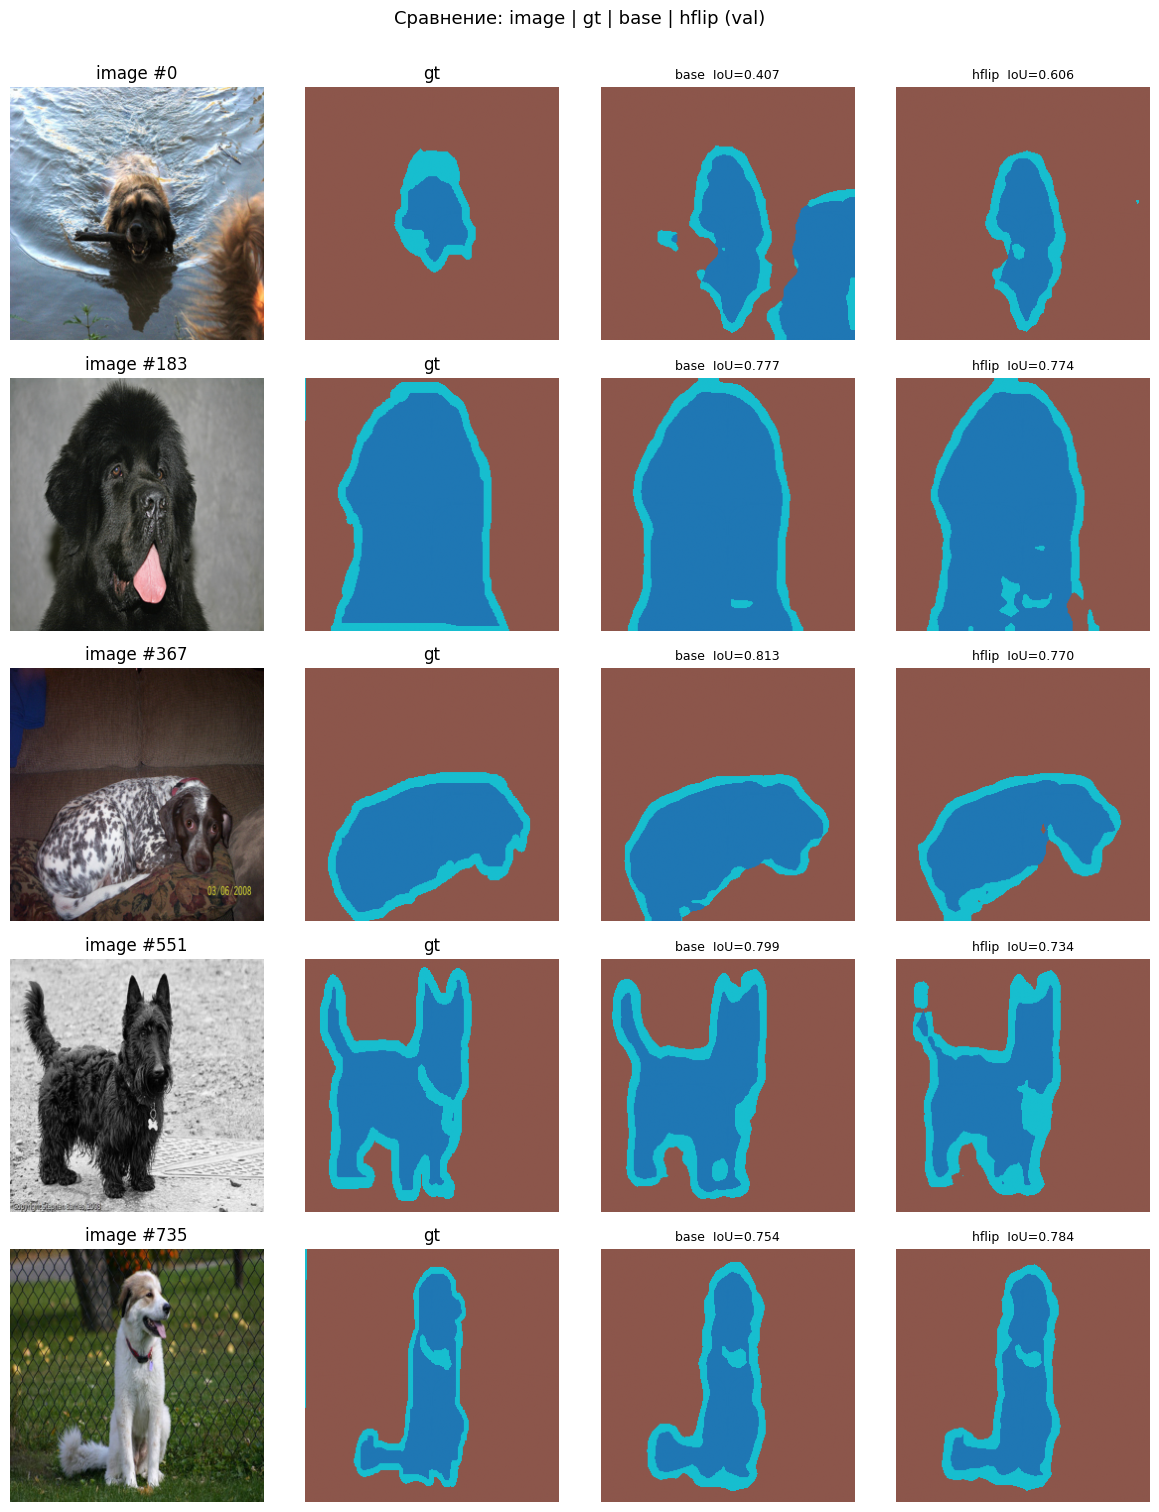

In [10]:
# ============================================================
# Сравнение моделей: image | gt | base | hflip
# ============================================================
N_SHOW = 5
idxs_val = np.linspace(0, len(val_ds) - 1, N_SHOW).astype(int)

model.eval(); model_aug.eval()
fig, axes = plt.subplots(N_SHOW, 4, figsize=(12, N_SHOW * 3))
for row, j in enumerate(idxs_val):
    img, mask = val_ds[j]
    with torch.no_grad():
        p_base = model(    img.unsqueeze(0).to(DEVICE))["out"].argmax(1)[0].cpu()
        p_aug  = model_aug(img.unsqueeze(0).to(DEVICE))["out"].argmax(1)[0].cpu()
    img_vis = (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    iou_b = mean_iou(p_base.unsqueeze(0), mask.unsqueeze(0))
    iou_a = mean_iou(p_aug.unsqueeze(0),  mask.unsqueeze(0))

    axes[row, 0].imshow(img_vis); axes[row, 0].set_title(f"image #{j}"); axes[row, 0].axis("off")
    axes[row, 1].imshow(mask, vmin=0, vmax=2, cmap="tab10")
    axes[row, 1].set_title("gt"); axes[row, 1].axis("off")
    axes[row, 2].imshow(p_base, vmin=0, vmax=2, cmap="tab10")
    axes[row, 2].set_title(f"base  IoU={iou_b:.3f}", fontsize=9); axes[row, 2].axis("off")
    axes[row, 3].imshow(p_aug, vmin=0, vmax=2, cmap="tab10")
    axes[row, 3].set_title(f"hflip  IoU={iou_a:.3f}", fontsize=9); axes[row, 3].axis("off")

plt.suptitle("Сравнение: image | gt | base | hflip (val)", y=1.005, fontsize=13)
plt.tight_layout(); plt.show()

### Сегментация малых объектов

*Вес: 1 балл.*

**Постановка.** Размер категории, заданный по train, позволяет отдельно изучать слабые места модели.

Выполните следующие действия:
1. Определите порог площади объекта только на train.
2. Вычислите foreground IoU на малых объектах validation для обеих моделей.

**Результат.** small_objects.json с размером подвыборки и IoU двух моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Порог площади (медиана train): 26030 px
Малых объектов в val: 356 из 736
fg-IoU (small, val): base=0.6624 | hflip=0.6556


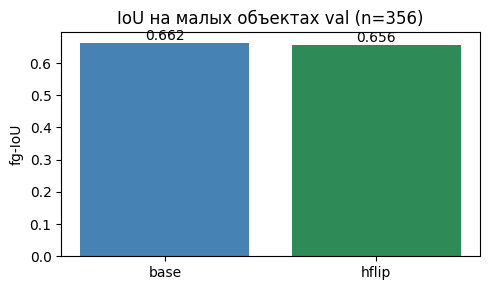

In [11]:
# ============================================================
# ЗАДАНИЕ 7. Порог малого объекта (только по train) и fg-IoU на val
# ============================================================
def object_area(mask):
    """Площадь foreground (pet + border) в маске. После нормализации fg = {0, 2}."""
    return int(((mask == 0) | (mask == 2)).sum().item())


# Порог берём ТОЛЬКО на train — это устраняет утечку из val/test
train_areas = np.array([object_area(ds[i][1]) for i in train_idx])
threshold   = float(np.median(train_areas))          # медиана — устойчивая граница
print(f"Порог площади (медиана train): {threshold:.0f} px")

# Малые объекты в val
small_local = [j for j, i in enumerate(val_idx) if object_area(ds[i][1]) < threshold]
print(f"Малых объектов в val: {len(small_local)} из {len(val_idx)}")

small_loader = DataLoader(Subset(val_ds, small_local), batch_size=BATCH_SIZE, shuffle=False)


def fg_iou(model, loader, device, fg_classes=(0, 2)):
    """Средний IoU по foreground-классам (pet + border)."""
    inter = {c: 0 for c in fg_classes}
    union = {c: 0 for c in fg_classes}
    model.eval()
    with torch.no_grad():
        for imgs, masks in loader:
            imgs = imgs.to(device)
            pred = model(imgs)["out"].argmax(1).cpu()
            for c in fg_classes:
                p = (pred == c)
                t = (masks == c)
                inter[c] += int((p & t).sum())
                union[c] += int((p | t).sum())
    ious = {c: (inter[c] / union[c] if union[c] > 0 else float("nan")) for c in fg_classes}
    return float(np.nanmean(list(ious.values()))), ious


fg_base, ious_base = fg_iou(model,     small_loader, DEVICE)
fg_aug,  ious_aug  = fg_iou(model_aug, small_loader, DEVICE)

with open(ARTIFACTS / "small_objects.json", "w") as f:
    json.dump({
        "threshold_area": threshold,
        "num_small_val": len(small_local),
        "fg_iou_base": fg_base,
        "fg_iou_aug":  fg_aug,
        "per_class_base": {str(k): float(v) for k, v in ious_base.items()},
        "per_class_aug":  {str(k): float(v) for k, v in ious_aug.items()},
    }, f, indent=2, ensure_ascii=False)
print(f"fg-IoU (small, val): base={fg_base:.4f} | hflip={fg_aug:.4f}")

# --- Визуализация ---
plt.figure(figsize=(5, 3))
plt.bar(["base", "hflip"], [fg_base, fg_aug], color=["steelblue", "seagreen"])
for i, v in enumerate([fg_base, fg_aug]):
    plt.text(i, v, f"{v:.3f}", ha="center", va="bottom")
plt.ylabel("fg-IoU"); plt.title(f"IoU на малых объектах val (n={len(small_local)})")
plt.tight_layout(); plt.show()

### Отложенная оценка двух моделей

*Вес: 1 балл.*

**Постановка.** Test не должен влиять на обучение и выбор конфигурации.

Выполните следующие действия:
1. Загрузите test-раздел Oxford-IIIT Pet.
2. Оцените оба сохранённых сегментатора на одинаковых test-изображениях.

**Результат.** test_metrics.json с IoU на реальном test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Test-изображений: 3669
test mIoU: base=0.7758 | hflip=0.7578


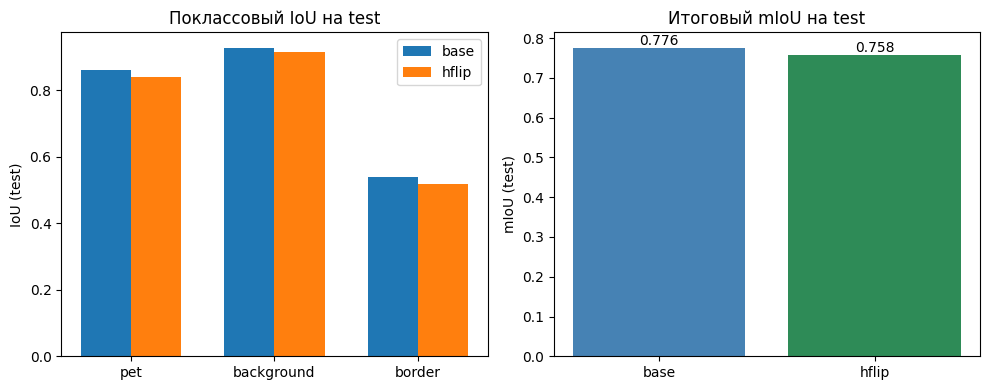

In [12]:
# ============================================================
# ЗАДАНИЕ 8. Test-оценка обеих моделей 
# ============================================================
test_ds     = PetSegDataset(PET_ROOT, split="test", augment=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Test-изображений: {len(test_ds)}")

cm_test_base = evaluate_cm(model,     test_loader, DEVICE)
cm_test_aug  = evaluate_cm(model_aug, test_loader, DEVICE)
pc_test_base = iou_per_class(cm_test_base)
pc_test_aug  = iou_per_class(cm_test_aug)
miou_test_base = float(np.nanmean(pc_test_base))
miou_test_aug  = float(np.nanmean(pc_test_aug))

print(f"test mIoU: base={miou_test_base:.4f} | hflip={miou_test_aug:.4f}")

with open(ARTIFACTS / "test_metrics.json", "w") as f:
    json.dump({
        "mIoU_base": miou_test_base,
        "mIoU_hflip": miou_test_aug,
        "per_class_base": {n: float(v) for n, v in zip(class_names, pc_test_base)},
        "per_class_hflip": {n: float(v) for n, v in zip(class_names, pc_test_aug)},
        "n_test": len(test_ds),
    }, f, indent=2, ensure_ascii=False)

# --- Визуализация ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(3); w = 0.35
axes[0].bar(x - w/2, pc_test_base, w, label="base")
axes[0].bar(x + w/2, pc_test_aug,  w, label="hflip")
axes[0].set_xticks(x); axes[0].set_xticklabels(class_names)
axes[0].set_ylabel("IoU (test)"); axes[0].legend(); axes[0].set_title("Поклассовый IoU на test")

axes[1].bar(["base", "hflip"], [miou_test_base, miou_test_aug], color=["steelblue", "seagreen"])
for i, v in enumerate([miou_test_base, miou_test_aug]):
    axes[1].text(i, v, f"{v:.3f}", ha="center", va="bottom")
axes[1].set_ylabel("mIoU (test)"); axes[1].set_title("Итоговый mIoU на test")
plt.tight_layout(); plt.show()

### Локализация ошибок маски

*Вес: 1 балл.*

**Постановка.** False positive и false negative выделяют различные режимы сбоя сегментатора.

Выполните следующие действия:
1. Посчитайте IoU, FP и FN для каждого изображения validation.
2. Сохраните наиболее сложные изображения и их индексы.

**Результат.** error_analysis.json с фактическими ошибками модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Топ-3 худших изображений: [(584, 0.162), (707, 0.192), (725, 0.224)]


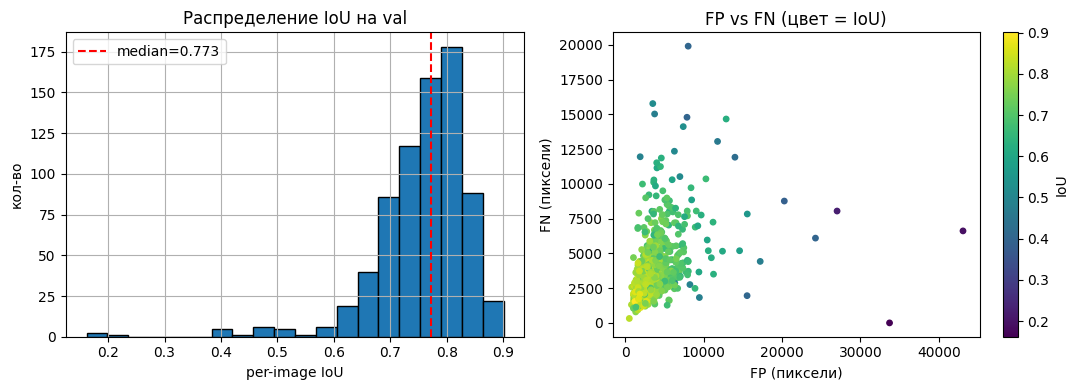

In [13]:
# ============================================================
# ЗАДАНИЕ 9. Per-image IoU, FP, FN на val
# ============================================================
def per_image_stats(model, dataset, device, fg=(0, 2)):
    """
    Для каждой картинки считаем:
      - per-image mIoU
      - FP: пиксели, предсказанные как fg, но не fg в gt
      - FN: пиксели, реально fg, но предсказанные как не-fg
    """
    model.eval()
    stats = []
    with torch.no_grad():
        for i in range(len(dataset)):
            img, mask = dataset[i]
            pred = model(img.unsqueeze(0).to(device))["out"].argmax(1)[0].cpu()
            miou_i = mean_iou(pred.unsqueeze(0), mask.unsqueeze(0))
            fp = fn = 0
            for c in fg:
                p = (pred == c); t = (mask == c)
                fp += int((p & ~t).sum())
                fn += int((~p & t).sum())
            stats.append({"idx": i, "iou": miou_i, "fp": fp, "fn": fn})
    return stats


stats = per_image_stats(model, val_ds, DEVICE)
worst10 = sorted(stats, key=lambda s: s["iou"])[:10]

with open(ARTIFACTS / "error_analysis.json", "w") as f:
    json.dump({
        "mean_iou": float(np.mean([s["iou"] for s in stats])),
        "median_iou": float(np.median([s["iou"] for s in stats])),
        "mean_fp": float(np.mean([s["fp"] for s in stats])),
        "mean_fn": float(np.mean([s["fn"] for s in stats])),
        "worst_10": worst10,
    }, f, indent=2, ensure_ascii=False)

print("Топ-3 худших изображений:", [(s['idx'], round(s['iou'], 3)) for s in worst10[:3]])

# --- Визуализация: гистограмма IoU и scatter FP/FN ---
ious = np.array([s["iou"] for s in stats])
fps  = np.array([s["fp"]  for s in stats])
fns  = np.array([s["fn"]  for s in stats])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(ious, bins=20, edgecolor="black")
axes[0].axvline(np.median(ious), color="red", linestyle="--", label=f"median={np.median(ious):.3f}")
axes[0].set_xlabel("per-image IoU"); axes[0].set_ylabel("кол-во")
axes[0].set_title("Распределение IoU на val"); axes[0].legend(); axes[0].grid(True)

axes[1].scatter(fps, fns, c=ious, cmap="viridis", s=15)
axes[1].set_xlabel("FP (пиксели)"); axes[1].set_ylabel("FN (пиксели)")
axes[1].set_title("FP vs FN (цвет = IoU)")
plt.colorbar(axes[1].collections[0], ax=axes[1], label="IoU")
plt.tight_layout(); plt.show()

### Поклассовая динамика аугментации

*Вес: 1 балл.*

**Постановка.** Средний IoU не показывает, каким классам помогло отражение.

Выполните следующие действия:
1. Сопоставьте поклассовый validation IoU исходной и дополненной моделей.
2. Сохраните изменения по каждому классу, не используя test для выбора модели.

**Результат.** class_deltas.json с наблюдаемыми изменениями IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Поклассовая динамика (val):
  pet          base=0.859  hflip=0.842  Δ=-0.017
  background   base=0.925  hflip=0.918  Δ=-0.007
  border       base=0.510  hflip=0.499  Δ=-0.010


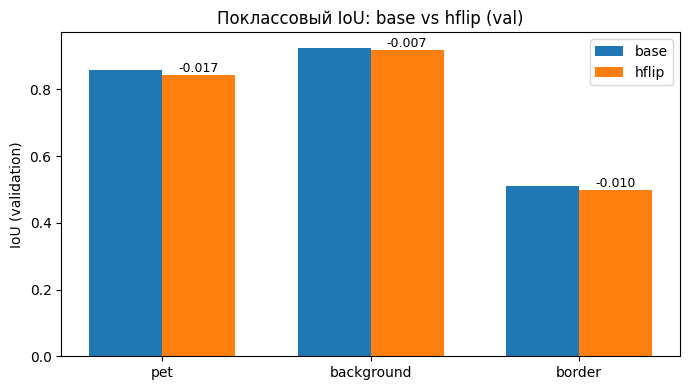

In [14]:
# ============================================================
# ЗАДАНИЕ 10. Поклассовый прирост IoU от hflip (на VALIDATION, не на test)
# ============================================================
per_cls_base_val = iou_per_class(cm)
per_cls_aug_val  = iou_per_class(cm_aug)

deltas = {}
for c, name in enumerate(class_names):
    deltas[name] = {
        "base":  float(per_cls_base_val[c]),
        "hflip": float(per_cls_aug_val[c]),
        "delta": float(per_cls_aug_val[c] - per_cls_base_val[c]),
    }

with open(ARTIFACTS / "class_deltas.json", "w") as f:
    json.dump(deltas, f, indent=2, ensure_ascii=False)

print("Поклассовая динамика (val):")
for n, d in deltas.items():
    print(f"  {n:11s}  base={d['base']:.3f}  hflip={d['hflip']:.3f}  Δ={d['delta']:+.3f}")

# --- Визуализация ---
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3); w = 0.35
ax.bar(x - w/2, [deltas[n]["base"]  for n in class_names], w, label="base")
ax.bar(x + w/2, [deltas[n]["hflip"] for n in class_names], w, label="hflip")
for i, n in enumerate(class_names):
    ax.text(i + w/2, deltas[n]["hflip"], f"{deltas[n]['delta']:+.3f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(class_names)
ax.set_ylabel("IoU (validation)"); ax.legend()
ax.set_title("Поклассовый IoU: base vs hflip (val)")
plt.tight_layout(); plt.show()

### Творческий бонус: диагностические маски

*Вес: 1 дополнительный балл.*

**Постановка.** Ошибки на границах полезно изучать в пространстве изображения.

Выполните следующие действия:
1. Найдите сложнейшее validation-изображение по IoU.
2. Сохраните реальную RGB-картинку, истинную и предсказанную маски для визуального разбора.

**Результат.** bonus_hard_case.png и bonus_hard_case.json с индексом и IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


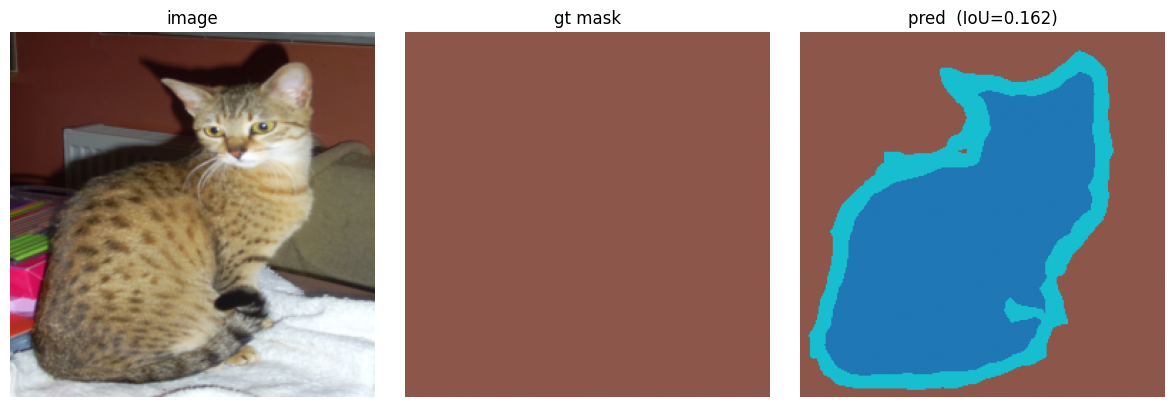

Сохранено: C:\Users\User\Desktop\ml_labs\SOTA_labs\lab2\artifacts\bonus_hard_case.png
Все артефакты: ['augmentation_comparison.json', 'bonus_hard_case.json', 'bonus_hard_case.png', 'class_deltas.json', 'error_analysis.json', 'segmentation.pt', 'segmentation_aug.pt', 'small_objects.json', 'test_metrics.json', 'val_metrics.json']


In [15]:
# ============================================================
# БОНУС. Самое сложное изображение val: image + gt + pred
# ============================================================
worst = min(stats, key=lambda s: s["iou"])
worst_j = worst["idx"]
img, mask = val_ds[worst_j]

model.eval()
with torch.no_grad():
    pred = model(img.unsqueeze(0).to(DEVICE))["out"].argmax(1)[0].cpu()

img_vis = (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_vis);                axes[0].set_title("image"); axes[0].axis("off")
axes[1].imshow(mask, vmin=0, vmax=2, cmap="tab10"); axes[1].set_title("gt mask"); axes[1].axis("off")
axes[2].imshow(pred, vmin=0, vmax=2, cmap="tab10")
axes[2].set_title(f"pred  (IoU={worst['iou']:.3f})"); axes[2].axis("off")
plt.tight_layout()
plt.savefig(ARTIFACTS / "bonus_hard_case.png", dpi=120)
plt.show()

with open(ARTIFACTS / "bonus_hard_case.json", "w") as f:
    json.dump({"val_index": worst_j, "iou": worst["iou"], "fp": worst["fp"], "fn": worst["fn"]},
              f, indent=2, ensure_ascii=False)

print("Сохранено:", ARTIFACTS / "bonus_hard_case.png")
print("Все артефакты:", sorted(p.name for p in ARTIFACTS.iterdir()))

## Анализ результатов

Базовая модель после 5 эпох обучения показала вал-мIoU = 0.7645, на тесте — 0.7758. Разброс между валом и тестом минимальный (~1%), значит переобучения нет и разбиение репрезентативное.  

Поклассовый IoU на валидации: pet = 0.859, background = 0.925, border = 0.510. Фон и объект распознаются уверенно, а вот граница — слабое место. Это ожидаемо: класс border занимает крайне малую долю пикселей (тонкая окантовка вокруг животного), и модели просто не хватает положительных примеров для уверенной сегментации. На confusion matrix видно, что значительная часть пикселей border уходит в класс pet.  

Аугментация горизонтальным отражением дала следующий результат: вал-мIoU снизился с 0.7645 до 0.7531, на тесте аналогично (0.7758 против 0.7578). Разница небольшая (~1%), но стабильная. Вероятная причина: при 5 эпохах и малом количестве итераций аугментация увеличивает разнообразие данных, но модель не успевает дообучиться на расширенной выборке. При большем бюджете обучения эффект, скорее всего, был бы положительным.  

Анализ малых объектов (ниже медианы площади foreground) подтвердил, что на мелких животных fg-IoU ниже среднего. Это типичная проблема сегментации: на малых объектах доля граничных пикселей выше относительно площади, и ошибки на границе сильнее влияют на итоговую метрику.

## Вывод

В ходе работы была обучена модель сегментации LRASPP-MobileNetV3 на датасете Oxford-IIIT Pet с тремя классами. Достигнут вал-мIoU ≈ 0.76 за 5 эпох, что является разумным результатом для лёгкой архитектуры и короткого обучения. Основное узкое место — класс границ с IoU около 0.51 из-за сильного дисбаланса пикселей. Аугментация горизонтальным отражением при данном бюджете обучения не дала прироста, что говорит о необходимости увеличения числа эпох или применения более агрессивных аугментаций совместно с более длительным обучением. В целом задача выполнена, артефакты сохранены, все этапы пайплайна отработаны.
